# 07. ROC-AUC và AP theo nhóm khi chuyển nguồn dữ liệu

Chạy lần lượt từ trên xuống. Trong VS Code, chọn kernel `.venv312\Scripts\python.exe` của repository.

**Mục tiêu:** đối chiếu khả năng xếp hạng của LR và XGBoost trên NHANES (outer-fold OOF) và BRFSS 2017 (kiểm định ngoài), theo giới tính, chủng tộc, tuổi và BMI.

- Dùng điểm dự đoán liên tục, không đọc cột nhãn dự đoán sau ngưỡng.
- AP là Average Precision từng nhóm. Macro AP là trung bình cộng AP của các nhóm định trước thuộc cùng một đặc trưng.
- Chênh lệch hiệu năng là dấu hiệu để nghiên cứu tiếp, chưa chứng minh nguyên nhân thiên kiến.
- Notebook tạo ước lượng điểm. CI và phân tích nguyên nhân là bước tiếp theo. Không huấn luyện hoặc hiệu chỉnh mô hình tại đây.

## Bước 1 — Chuẩn bị thư viện và đường dẫn

Cell này tìm thư mục dự án để notebook chạy được từ thư mục repository hoặc notebooks. Kiểm tra Python in ra thuộc môi trường `.venv312`. Dùng lại hàm chia nhóm từ `src/utils.py` để giữ định nghĩa thống nhất.

In [18]:
from pathlib import Path
import sys
import json
import hashlib

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from sklearn.metrics import roc_auc_score, average_precision_score

project_dir = next(
    p for p in [Path.cwd(), *Path.cwd().parents]
    if (p / 'data/processed').is_dir() and (p / 'src').is_dir()
)
if str(project_dir) not in sys.path:
    sys.path.insert(0, str(project_dir))

from src.utils import get_fairness_groups, get_fairness_group_specs

MODELS = ['XGBoost', 'LR']
INTERNAL_RUN = '3d15f3dbb58256ec'
EXTERNAL_RUN = '54c463bbe9079503'
output_dir = project_dir / 'results/auc_ap_dataset_shift'

print('Python:', sys.executable)
print('Project:', project_dir)
print('Định nghĩa nhóm:', get_fairness_group_specs()[0])

Python: d:\nckh\diabetes-ml-fairness\.venv312\Scripts\python.exe
Project: d:\nckh\diabetes-ml-fairness\diabetes-project
Định nghĩa nhóm: {'race_ethnicity': ['White NH', 'Black NH', 'Hispanic', 'Other'], 'age': ['18-39', '40-59', '60+'], 'bmi': ['Underweight', 'Normal', 'Overweight', 'Obese']}


## Bước 2 — Xác định đúng nguồn dự đoán

**NHANES:** `results/tuning/3d15f3dbb58256ec/oof_*.parquet`, mỗi người có một dự đoán outer-fold từ mô hình không học hoặc tuning trên người đó.

**BRFSS 2017:** dự đoán ngoài thuộc final run `54c463bbe9079503`. Hai ID khác nhau vì một ID thuộc giai đoạn nested CV, một ID thuộc giai đoạn mô hình cuối.

Mô hình `.joblib` hiện có thuộc run `9dafe348742a3e02`. Notebook này phân tích các dự đoán cũ đã lưu, **không gán chúng cho file mô hình hiện tại**. So sánh nội bộ/ngoài đánh giá quy trình học, không phải cùng một mô hình đã fit: OOF đến từ các mô hình vòng ngoài, BRFSS từ mô hình cuối.

Không dùng `final_development/*/development_oof.parquet` làm đánh giá nội bộ độc lập, vì file đó phục vụ phát triển ngưỡng sau khi chọn cấu hình.

In [19]:
source_paths = {
    'nhanes_processed': project_dir / 'data/processed/nhanes_2015_2018.parquet',
    'external_manifest': project_dir / f'results/external_validation/{EXTERNAL_RUN}/manifest.json',
    'group_definition': project_dir / 'src/utils.py',
}
for model in MODELS:
    source_paths[f'internal_{model}'] = project_dir / f'results/tuning/{INTERNAL_RUN}/oof_{model}.parquet'
    source_paths[f'external_{model}'] = project_dir / f'results/external_validation/{EXTERNAL_RUN}/brfss_2017_{model}_predictions.parquet'

for name, path in source_paths.items():
    if not path.is_file():
        raise FileNotFoundError(f'{name}: {path}')

external_manifest = json.loads(source_paths['external_manifest'].read_text(encoding='utf-8'))
assert external_manifest['final_run_id'] == EXTERNAL_RUN
display(pd.DataFrame([{'source': k, 'path': str(v.relative_to(project_dir))}
                      for k, v in source_paths.items()]))

,source,path
0,nhanes_processed,data\processed\nhanes_2015_2018.parquet
1,external_manifest,results\external_validation\54c463bbe9079503\m...
2,group_definition,src\utils.py
3,internal_XGBoost,results\tuning\3d15f3dbb58256ec\oof_XGBoost.pa...
4,external_XGBoost,results\external_validation\54c463bbe9079503\b...
5,internal_LR,results\tuning\3d15f3dbb58256ec\oof_LR.parquet
6,external_LR,results\external_validation\54c463bbe9079503\b...


## Bước 3 — Nối nhóm với dự đoán và kiểm tra dữ liệu

OOF NHANES chỉ có định danh và điểm; nối với dữ liệu đã xử lý bằng `SEQN` và `cycle`, không theo thứ tự dòng. BRFSS đã có các đặc trưng nhóm.

Sau cell này, mỗi bảng có `y_true`, `score`, `sex`, `race_ethnicity`, `age`, `bmi`. Các kiểm tra đảm bảo không mất người, không nối nhầm nhãn, điểm hữu hạn và hai mô hình đánh giá cùng những người.

In [20]:
nhanes = pd.read_parquet(source_paths['nhanes_processed'])
group_cols = ['sex', 'race_ethnicity', 'age', 'bmi']
evaluation_data = {}
cohort_ids = {}

for model in MODELS:
    oof = pd.read_parquet(source_paths[f'internal_{model}'])
    assert oof['run_id'].eq(INTERNAL_RUN).all()
    assert set(oof['outer_fold'].unique()) == {1, 2, 3, 4, 5}
    internal = oof.merge(
        nhanes[['SEQN', 'cycle', 'diabetes_label'] + group_cols],
        on=['SEQN', 'cycle'], how='left', validate='one_to_one', indicator=True,
    )
    assert len(internal) == len(nhanes) == 10832
    assert internal['_merge'].eq('both').all()
    assert internal['y_true'].eq(internal['diabetes_label']).all()

    external = pd.read_parquet(source_paths[f'external_{model}'])
    assert external['source_row_id'].is_unique
    assert external['year'].eq(2017).all()
    assert len(external) == 449219
    external = external.rename(columns={'diabetes_label': 'y_true', 'probability': 'score'})

    cohort_ids[('NHANES_OOF', model)] = set(zip(internal['SEQN'], internal['cycle']))
    cohort_ids[('BRFSS_2017', model)] = set(external['source_row_id'])
    for dataset, frame in [('NHANES_OOF', internal), ('BRFSS_2017', external)]:
        frame = frame[['y_true', 'score'] + group_cols].reset_index(drop=True).copy()
        assert frame['y_true'].notna().all() and frame['y_true'].isin([0, 1]).all()
        assert np.isfinite(frame['score'].to_numpy(dtype=float)).all()
        evaluation_data[(dataset, model)] = frame

for dataset in ['NHANES_OOF', 'BRFSS_2017']:
    assert cohort_ids[(dataset, 'LR')] == cohort_ids[(dataset, 'XGBoost')]

display(pd.DataFrame([
    {'dataset': dataset, 'model': model, 'n': len(frame),
     'n_positive': int(frame['y_true'].sum()), 'positive_rate': frame['y_true'].mean()}
    for (dataset, model), frame in evaluation_data.items()
]).round(4))

,dataset,model,n,n_positive,positive_rate
0,NHANES_OOF,XGBoost,10832,2274,0.2099
1,BRFSS_2017,XGBoost,449219,60440,0.1345
2,NHANES_OOF,LR,10832,2274,0.2099
3,BRFSS_2017,LR,449219,60440,0.1345


## Bước 4 — Tính ROC-AUC và AP toàn tập, theo nhóm

- ROC-AUC đánh giá thứ tự điểm giữa người có và không có nhãn bệnh.
- AP tóm tắt precision–recall bằng `average_precision_score`, không phải diện tích PR tính bằng quy tắc hình thang.
- Không cần ngưỡng Youden. Điểm đưa vào là `score` liên tục.
- Báo cáo tỷ lệ bệnh cùng AP vì AP phụ thuộc tỷ lệ lớp dương.
- Giữ cả nhóm thiếu dữ liệu và BMI thiếu cân trong mô tả. Nếu thiếu một lớp, để chỉ số là NA và ghi trạng thái, không gán 0.

Khi rerun cell này sau khi chỉnh hàm, kết quả sẽ được tính lại từ các dự đoán đã đọc.

In [21]:
def summarize_scores(frame):
    y = frame['y_true'].to_numpy(dtype=int)
    score = frame['score'].to_numpy(dtype=float)
    valid = np.unique(y).size == 2
    return {
        'n': len(y), 'n_positive': int(y.sum()),
        'n_negative': int(len(y) - y.sum()),
        'positive_rate': float(y.mean()) if len(y) else np.nan,
        'roc_auc': roc_auc_score(y, score) if valid else np.nan,
        'ap': average_precision_score(y, score) if valid else np.nan,
        'status': 'ok' if valid else 'Không đủ hai lớp',
    }

def evaluate_dataset(frame, dataset, model):
    groups, specs = get_fairness_groups(frame)
    assert frame['sex'].dropna().isin([1, 2]).all()
    groups['sex'] = frame['sex'].map({1: 'Nam', 2: 'Nữ'}).astype('string').fillna('Missing')
    specs = {'sex': ['Nam', 'Nữ'], **specs}
    rows = [{'dataset': dataset, 'model': model, 'attribute': 'overall',
             'group': 'All', **summarize_scores(frame)}]
    for attribute, labels in specs.items():
        for label in labels + ['Missing']:
            subset = frame.loc[groups[attribute].eq(label)]
            rows.append({'dataset': dataset, 'model': model, 'attribute': attribute,
                         'group': label, **summarize_scores(subset)})
    return pd.DataFrame(rows)

metrics = pd.concat([
    evaluate_dataset(frame, dataset, model)
    for (dataset, model), frame in evaluation_data.items()
], ignore_index=True)

for (dataset, model), block in metrics.groupby(['dataset', 'model']):
    n_total = int(block.loc[block['attribute'].eq('overall'), 'n'].iloc[0])
    for attribute in ['sex', 'age', 'bmi', 'race_ethnicity']:
        assert block.loc[block['attribute'].eq(attribute), 'n'].sum() == n_total

display(metrics.query("attribute == 'overall'").round(4))
display(metrics.query("attribute == 'age' and group != 'Missing'").round(4))

,dataset,model,attribute,group,n,n_positive,n_negative,positive_rate,roc_auc,ap,status
0,NHANES_OOF,XGBoost,overall,All,10832,2274,8558,0.2099,0.7999,0.4784,ok
18,BRFSS_2017,XGBoost,overall,All,449219,60440,388779,0.1345,0.7691,0.3218,ok
36,NHANES_OOF,LR,overall,All,10832,2274,8558,0.2099,0.7950,0.4617,ok
54,BRFSS_2017,LR,overall,All,449219,60440,388779,0.1345,0.7722,0.3293,ok


,dataset,model,attribute,group,n,n_positive,n_negative,positive_rate,roc_auc,ap,status
9,NHANES_OOF,XGBoost,age,18-39,3720,170,3550,0.0457,0.7688,0.1664,ok
10,NHANES_OOF,XGBoost,age,40-59,3339,684,2655,0.2049,0.7032,0.3759,ok
11,NHANES_OOF,XGBoost,age,60+,3773,1420,2353,0.3764,0.6753,0.5314,ok
27,BRFSS_2017,XGBoost,age,18-39,99769,2300,97469,0.0231,0.7263,0.0823,ok
28,BRFSS_2017,XGBoost,age,40-59,140691,16128,124563,0.1146,0.7357,0.2722,ok
29,BRFSS_2017,XGBoost,age,60+,208759,42012,166747,0.2012,0.6912,0.3464,ok
45,NHANES_OOF,LR,age,18-39,3720,170,3550,0.0457,0.7653,0.1578,ok
46,NHANES_OOF,LR,age,40-59,3339,684,2655,0.2049,0.7048,0.3781,ok
47,NHANES_OOF,LR,age,60+,3773,1420,2353,0.3764,0.6606,0.5098,ok
63,BRFSS_2017,LR,age,18-39,99769,2300,97469,0.0231,0.7279,0.0826,ok


### Biểu đồ đối chiếu ROC-AUC nội bộ và ngoài theo từng nhóm

Mỗi ô là một đặc trưng của một mô hình. Hai cột cạnh nhau biểu diễn **NHANES OOF** và **BRFSS 2017** của cùng nhóm. Giá trị trên đầu cột là ROC-AUC của nhóm đó.

- Xem nhóm nào có AUC ngoài thấp hơn nội bộ và mức không đồng đều giữa các nhóm.
- Trục ROC-AUC thống nhất 0–1. Đường 0,5 là mốc xếp hạng ngẫu nhiên.
- BMI thiếu cân được giữ để mô tả; macro AP chính ở Bước 6 vẫn chỉ dùng ba nhóm BMI chính.
- Mặc định không vẽ Missing. Đổi `SHOW_MISSING_AUC = True` nếu muốn xem. NA nghĩa là không đủ hai lớp để tính AUC.
- Đây là ước lượng điểm, chưa có CI. Chênh lệch cột chưa tự chứng minh ý nghĩa thống kê hoặc nguyên nhân bias.

Biểu đồ dùng `metrics` vừa tính ở trên, không cần chạy Bước 5 trước.

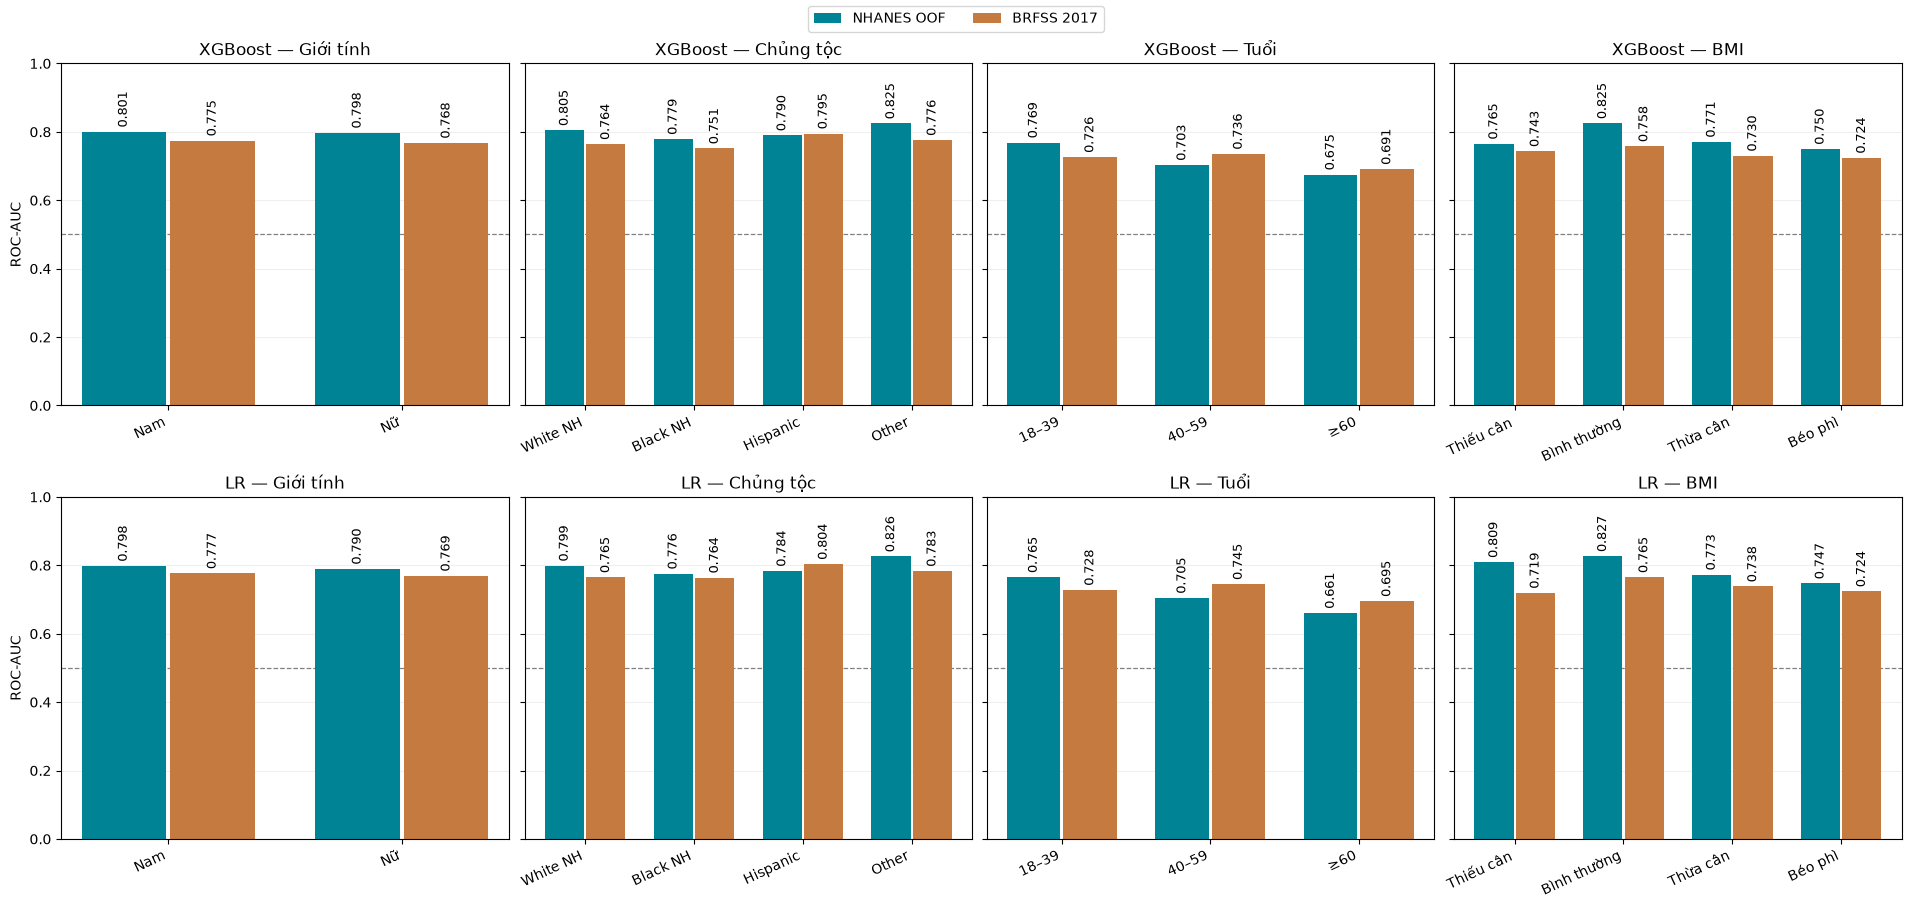

In [22]:
SHOW_MISSING_AUC = False

auc_specs, _ = get_fairness_group_specs()
auc_specs = {'sex': ['Nam', 'Nữ'], **auc_specs}
attribute_names = {
    'sex': 'Giới tính', 'race_ethnicity': 'Chủng tộc',
    'age': 'Tuổi', 'bmi': 'BMI',
}
group_names = {
    '18-39': '18–39', '40-59': '40–59', '60+': '≥60',
    'Underweight': 'Thiếu cân', 'Normal': 'Bình thường',
    'Overweight': 'Thừa cân', 'Obese': 'Béo phì', 'Missing': 'Thiếu dữ liệu',
}

auc_group_fig, auc_axes = plt.subplots(
    len(MODELS), len(auc_specs), figsize=(19, 4.5 * len(MODELS)),
    squeeze=False, sharey=True, constrained_layout=True,
)
for row, model in enumerate(MODELS):
    for col, (attribute, labels) in enumerate(auc_specs.items()):
        ax = auc_axes[row, col]
        labels = labels + (['Missing'] if SHOW_MISSING_AUC else [])
        block = metrics.loc[
            metrics['model'].eq(model) & metrics['attribute'].eq(attribute)
        ]
        assert not block.duplicated(['group', 'dataset']).any()
        auc_values = block.pivot(index='group', columns='dataset', values='roc_auc')
        auc_values = auc_values.reindex(labels)
        x = np.arange(len(labels))
        for dataset, offset, color, legend in [
            ('NHANES_OOF', -0.19, '#008495', 'NHANES OOF'),
            ('BRFSS_2017', 0.19, '#C57B3F', 'BRFSS 2017'),
        ]:
            values = auc_values[dataset].to_numpy(dtype=float)
            bars = ax.bar(x + offset, values, width=0.36, color=color, label=legend)
            ax.bar_label(bars, labels=[f'{v:.3f}' if np.isfinite(v) else 'NA'
                                       for v in values], padding=3, fontsize=9,
                         rotation=90)
        ax.axhline(0.5, color='gray', linestyle='--', linewidth=0.9, zorder=0)
        ax.set_xticks(x, [group_names.get(g, g) for g in labels],
                      rotation=25, ha='right')
        ax.set_ylim(0, 1)
        ax.set_title(f'{model} — {attribute_names[attribute]}')
        ax.set_axisbelow(True)
        ax.grid(axis='y', alpha=0.2)
        if col == 0:
            ax.set_ylabel('ROC-AUC')
handles, legend_labels = auc_axes[0, 0].get_legend_handles_labels()
auc_group_fig.legend(handles, legend_labels, loc='outside upper center', ncol=2)
plt.show()


## Bước 5 — Đối chiếu nội bộ và ngoài trong từng nhóm

`delta_auc = AUC ngoài − AUC nội bộ`, tương tự với AP. Số âm biểu thị suy giảm ước lượng điểm. `delta_positive_rate` giúp nhận biết thay đổi tỷ lệ bệnh đi kèm. Các delta là chênh đơn vị chỉ số, không phải phần trăm thay đổi tương đối.

Đổi `ATTRIBUTE` thành `sex`, `race_ethnicity`, `age`, `bmi` hoặc `overall` để xem bảng. Thay `MODEL` để đối chiếu LR và XGBoost. Chưa có CI nên chưa kết luận ý nghĩa thống kê từ delta.

In [23]:
keys = ['model', 'attribute', 'group']
values = ['n', 'n_positive', 'positive_rate', 'roc_auc', 'ap', 'status']
left = metrics.loc[metrics['dataset'].eq('NHANES_OOF'), keys + values]
right = metrics.loc[metrics['dataset'].eq('BRFSS_2017'), keys + values]
comparison = left.merge(right, on=keys, how='outer', validate='one_to_one',
                        suffixes=('_internal', '_external'))
for metric in ['roc_auc', 'ap', 'positive_rate']:
    name = 'auc' if metric == 'roc_auc' else metric
    comparison[f'delta_{name}'] = comparison[f'{metric}_external'] - comparison[f'{metric}_internal']

ATTRIBUTE = 'age'
MODEL = 'XGBoost'
selected = comparison.loc[(comparison['attribute'] == ATTRIBUTE) & (comparison['model'] == MODEL)]
display(selected.round(4))

# Các nhóm suy giảm AUC nhiều nhất của từng mô hình (bỏ nhóm mô tả phụ).
primary_mask = ~comparison['group'].isin(['Missing', 'Underweight', 'All'])
display(comparison.loc[primary_mask].sort_values('delta_auc')[
    keys + ['roc_auc_internal', 'roc_auc_external', 'delta_auc',
            'ap_internal', 'ap_external', 'delta_ap',
            'positive_rate_internal', 'positive_rate_external']
].round(4))

,model,attribute,group,n_internal,n_positive_internal,positive_rate_internal,roc_auc_internal,ap_internal,status_internal,n_external,n_positive_external,positive_rate_external,roc_auc_external,ap_external,status_external,delta_auc,delta_ap,delta_positive_rate
18,XGBoost,age,18-39,3720,170,0.0457,0.7688,0.1664,ok,99769,2300,0.0231,0.7263,0.0823,ok,-0.0425,-0.0841,-0.0226
19,XGBoost,age,40-59,3339,684,0.2049,0.7032,0.3759,ok,140691,16128,0.1146,0.7357,0.2722,ok,0.0325,-0.1037,-0.0902
20,XGBoost,age,60+,3773,1420,0.3764,0.6753,0.5314,ok,208759,42012,0.2012,0.6912,0.3464,ok,0.0159,-0.1850,-0.1751
21,XGBoost,age,Missing,0,0,NaN,NaN,NaN,Không đủ hai lớp,0,0,NaN,NaN,NaN,Không đủ hai lớp,NaN,NaN,NaN


,model,attribute,group,roc_auc_internal,roc_auc_external,delta_auc,ap_internal,ap_external,delta_ap,positive_rate_internal,positive_rate_external
23,XGBoost,bmi,Normal,0.8250,0.7578,-0.0672,0.3161,0.1648,-0.1513,0.0990,0.0612
5,LR,bmi,Normal,0.8267,0.7651,-0.0616,0.3035,0.1698,-0.1338,0.0990,0.0612
31,XGBoost,race_ethnicity,Other,0.8245,0.7760,-0.0485,0.5040,0.3496,-0.1544,0.1985,0.1504
13,LR,race_ethnicity,Other,0.8259,0.7834,-0.0425,0.4927,0.3602,-0.1325,0.1985,0.1504
18,XGBoost,age,18-39,0.7688,0.7263,-0.0425,0.1664,0.0823,-0.0841,0.0457,0.0231
25,XGBoost,bmi,Overweight,0.7708,0.7301,-0.0408,0.3772,0.2455,-0.1316,0.1816,0.1187
32,XGBoost,race_ethnicity,White NH,0.8048,0.7641,-0.0407,0.4529,0.3045,-0.1484,0.1839,0.1255
0,LR,age,18-39,0.7653,0.7279,-0.0374,0.1578,0.0826,-0.0751,0.0457,0.0231
7,LR,bmi,Overweight,0.7727,0.7381,-0.0346,0.3853,0.2513,-0.1340,0.1816,0.1187
14,LR,race_ethnicity,White NH,0.7987,0.7650,-0.0338,0.4333,0.3084,-0.1249,0.1839,0.1255


## Bước 6 — Macro AP giữa các nhóm (nếu cần gọi mAP)

Tính trung bình cộng AP các nhóm của **từng đặc trưng riêng biệt**, mỗi nhóm trọng số bằng nhau. Ví dụ macro AP giới tính = (AP nam + AP nữ)/2.

Các nhóm chính: giới tính 2, chủng tộc 4, tuổi 3, BMI 3 (bình thường/thừa cân/béo phì). Missing và thiếu cân không tham gia macro AP chính. Không âm thầm bỏ nhóm có AP không xác định. Macro AP không bằng AP toàn tập và không nên thay thế bảng từng nhóm.

In [24]:
_, primary_specs = get_fairness_group_specs()
primary_specs = {'sex': ['Nam', 'Nữ'], **primary_specs}
macro_rows = []
for (dataset, model), block in metrics.groupby(['dataset', 'model']):
    for attribute, expected in primary_specs.items():
        selected = block.loc[block['attribute'].eq(attribute)].set_index('group').reindex(expected)
        complete = selected['ap'].notna().all()
        macro_rows.append({
            'dataset': dataset, 'model': model, 'attribute': attribute,
            'n_groups': len(expected),
            'macro_ap': selected['ap'].mean() if complete else np.nan,
            'status': 'ok' if complete else 'Có nhóm thiếu AP',
        })
macro_ap = pd.DataFrame(macro_rows)
display(macro_ap.round(4))

,dataset,model,attribute,n_groups,macro_ap,status
0,BRFSS_2017,LR,sex,2,0.3306,ok
1,BRFSS_2017,LR,race_ethnicity,4,0.3597,ok
2,BRFSS_2017,LR,age,3,0.2410,ok
3,BRFSS_2017,LR,bmi,3,0.2770,ok
4,BRFSS_2017,XGBoost,sex,2,0.3239,ok
5,BRFSS_2017,XGBoost,race_ethnicity,4,0.3491,ok
6,BRFSS_2017,XGBoost,age,3,0.2336,ok
7,BRFSS_2017,XGBoost,bmi,3,0.2750,ok
8,NHANES_OOF,LR,sex,2,0.4610,ok
9,NHANES_OOF,LR,race_ethnicity,4,0.4669,ok


## Bước 7 — Vẽ kết quả để đọc mức chuyển nguồn

Chọn `PLOT_MODEL` và `PLOT_ATTRIBUTE`. Mỗi chấm biểu diễn một nhóm, đường nối chỉ để đối chiếu cùng nhóm trên hai nguồn. Trục chỉ số cố định từ 0 đến 1. AP cần đọc cùng bảng tỷ lệ bệnh, không kết luận bias chỉ từ chênh AP.

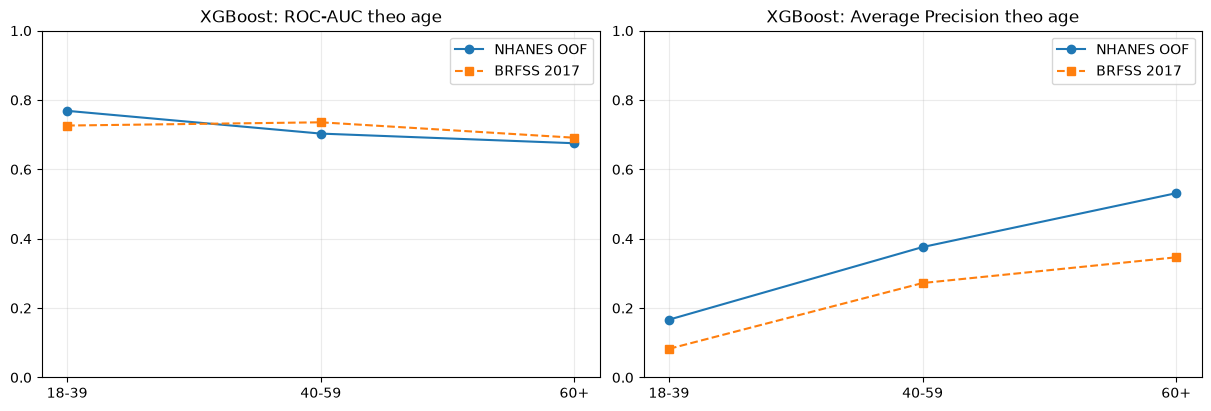

In [25]:
PLOT_MODEL = 'XGBoost'
PLOT_ATTRIBUTE = 'age'
plot_data = comparison.loc[
    comparison['model'].eq(PLOT_MODEL) & comparison['attribute'].eq(PLOT_ATTRIBUTE)
].set_index('group').reindex(primary_specs[PLOT_ATTRIBUTE])

fig, axes = plt.subplots(1, 2, figsize=(12, 4), constrained_layout=True)
x = np.arange(len(plot_data))
for ax, metric, title in zip(axes, ['roc_auc', 'ap'], ['ROC-AUC', 'Average Precision']):
    ax.plot(x, plot_data[f'{metric}_internal'], 'o-', label='NHANES OOF')
    ax.plot(x, plot_data[f'{metric}_external'], 's--', label='BRFSS 2017')
    ax.set_xticks(x, plot_data.index)
    ax.set_ylim(0, 1)
    ax.set_title(f'{PLOT_MODEL}: {title} theo {PLOT_ATTRIBUTE}')
    ax.grid(alpha=0.25)
    ax.legend()
plt.show()

## Bước 8 — Lưu kết quả và nguồn dữ liệu

Chỉ ghi vào `results/auc_ap_dataset_shift/`; không ghi đè các kết quả fairness cũ. Manifest ghi nguồn, run ID và SHA-256 các file đã dùng để lần sau kiểm tra được kết quả đến từ đâu. Không dùng `.joblib` hiện tại trong notebook này.

Ba CSV gồm kết quả từng nhóm, so sánh nội bộ/ngoài và macro AP. Hình lưu theo lựa chọn tại Bước 7. Rerun sẽ cập nhật các file cùng tên.

In [26]:
output_dir.mkdir(parents=True, exist_ok=True)
auc_group_fig.savefig(output_dir / 'auc_internal_external_all_groups.png', dpi=180, bbox_inches='tight')
metrics.to_csv(output_dir / 'auc_ap_by_group.csv', index=False, encoding='utf-8-sig')
comparison.to_csv(output_dir / 'internal_external_comparison.csv', index=False, encoding='utf-8-sig')
macro_ap.to_csv(output_dir / 'macro_ap_by_attribute.csv', index=False, encoding='utf-8-sig')
fig.savefig(output_dir / f'{PLOT_MODEL}_{PLOT_ATTRIBUTE}_auc_ap.png', dpi=180, bbox_inches='tight')

manifest = {
    'internal_run': INTERNAL_RUN, 'external_final_run': EXTERNAL_RUN,
    'models': MODELS, 'internal_prediction': 'outer-fold nested CV OOF',
    'external_prediction': 'saved frozen final-model predictions on BRFSS 2017',
    'threshold_used': False, 'survey_weighted': False,
    'uncertainty': 'point estimates only; no CI or significance tests here',
    'macro_ap_definition': 'unweighted mean AP of prespecified groups within each attribute',
    'primary_groups': primary_specs,
    'comparison_scope': 'learning procedure: outer-fold models internally versus final model externally',
    'sources_sha256': {str(p.relative_to(project_dir)): hashlib.sha256(p.read_bytes()).hexdigest()
                       for p in source_paths.values()},
}
(output_dir / 'manifest.json').write_text(json.dumps(manifest, ensure_ascii=False, indent=2), encoding='utf-8')
print('Đã lưu tại:', output_dir)

Đã lưu tại: d:\nckh\diabetes-ml-fairness\diabetes-project\results\auc_ap_dataset_shift


## Bước 9 — Đánh giá kết quả và định hướng nghiên cứu tiếp theo

**Phạm vi:** nhận xét dưới đây dựa trên kết quả đã chạy và xuất trong `results/auc_ap_dataset_shift/`: `auc_ap_by_group.csv`, `internal_external_comparison.csv` và `macro_ap_by_attribute.csv`. Nội bộ là NHANES outer-fold OOF, ngoài là BRFSS 2017. Delta = ngoài − nội bộ. Các kết luận là mô tả ước lượng điểm, chưa có CI hoặc kiểm định trong notebook này; không sử dụng ngưỡng phân loại. Nếu thay dữ liệu hoặc mô hình, cần cập nhật phần nhận xét này.

### 9.1. Hiệu năng tổng thể giảm khi chuyển nguồn, LR giữ kết quả ngoài tốt hơn theo các chỉ số đang xét

| Mô hình | AUC nội bộ | AUC ngoài | ΔAUC | AP nội bộ | AP ngoài | ΔAP |
|---|---:|---:|---:|---:|---:|---:|
| XGBoost | 0,7999 | 0,7691 | −0,0308 | 0,4784 | 0,3218 | −0,1566 |
| LR | 0,7950 | 0,7722 | −0,0228 | 0,4617 | 0,3293 | −0,1325 |

**Dẫn chứng và ý nghĩa:** XGBoost đứng cao hơn LR trong nội bộ nhưng LR nhỉnh hơn trên BRFSS 2017, cả AUC lẫn AP. Mức giảm AUC của LR cũng nhỏ hơn. Vì vậy, lợi thế nội bộ của XGBoost không chuyển nguyên vẹn sang nguồn ngoài; LR cần tiếp tục là đối chứng trong các thử nghiệm khắc phục. Chênh AUC ngoài giữa hai mô hình chỉ khoảng 0,0032, nên chưa thể gọi là ưu thế lớn hoặc khẳng định ý nghĩa thống kê từ notebook này.

Tỷ lệ bệnh của mẫu giảm từ **20,99% xuống 13,45%**, tương đương giảm 7,54 điểm phần trăm. AP nhạy với tỷ lệ lớp dương, nên mức giảm AP tổng thể chưa thể quy hoàn toàn cho khả năng xếp hạng hoặc bias. ROC-AUC cũng có thể thay đổi khi phân bố đặc trưng trong các lớp thay đổi; nó không tự miễn nhiễm với chuyển nguồn.

### 9.2. Nhóm có kết quả ngoài thấp nhất khác với nhóm suy giảm nhiều nhất

Trong các nhóm chính (không gồm Missing và BMI thiếu cân), **nhóm ≥60 có AUC ngoài thấp nhất**, khoảng 0,6912 với XGBoost và 0,6953 với LR. **Nhóm 18–39 có AP ngoài thấp nhất**, khoảng 0,0823 và 0,0826. Tuy nhiên, nhóm ≥60 không phải nhóm giảm AUC nhiều nhất khi chuyển nguồn: AUC của nhóm này thực tế tăng so với nội bộ.

| Nhóm | ΔAUC XGBoost | ΔAUC LR | Điều cần chú ý |
|---|---:|---:|---|
| BMI bình thường | −0,0672 | −0,0616 | Giảm AUC lớn nhất trong các nhóm chính ở cả hai mô hình |
| Chủng tộc Other | −0,0485 | −0,0425 | Cùng suy giảm ở hai mô hình, nhóm gộp có thể khác thành phần giữa hai nguồn |
| Tuổi 18–39 | −0,0425 | −0,0374 | Nhóm trẻ suy giảm khả năng phân biệt |
| BMI thừa cân | −0,0408 | −0,0346 | Suy giảm nhất quán ở hai mô hình |
| White NH | −0,0407 | −0,0338 | Suy giảm trong nhóm chiếm phần lớn mẫu ngoài |

**Ý nghĩa:** cần tách hai ưu tiên: nhóm có hiệu năng tuyệt đối thấp để tìm cách cải thiện, và nhóm mất nhiều hiệu năng khi chuyển nguồn để tìm nguyên nhân kém khái quát hóa. BMI bình thường và người trẻ là những đối tượng đáng ưu tiên cho câu hỏi thứ hai; nhóm ≥60 vẫn cần nghiên cứu vì khả năng phân biệt ngoài thấp.

### 9.3. Phân tích theo từng đặc trưng

**Tuổi: AUC và AP có xu hướng khác nhau.**

| Nhóm tuổi | AUC XGB nội bộ → ngoài | AP XGB nội bộ → ngoài | Tỷ lệ bệnh nội bộ → ngoài |
|---|---|---|---|
| 18–39 | 0,7688 → 0,7263 | 0,1664 → 0,0823 | 4,57% → 2,31% |
| 40–59 | 0,7032 → 0,7357 | 0,3759 → 0,2722 | 20,49% → 11,46% |
| ≥60 | 0,6753 → 0,6912 | 0,5314 → 0,3464 | 37,64% → 20,12% |

Ở người trẻ, AUC và AP đều giảm. Ở hai nhóm tuổi còn lại, AUC tăng nhưng AP giảm. LR có cùng hướng biến đổi: ΔAUC ba nhóm lần lượt −0,0374, +0,0402 và +0,0347. Vì vậy, không thể nói khả năng phân biệt giảm ở tất cả nhóm tuổi. AP giảm đồng thời với tỷ lệ bệnh giảm, phù hợp với việc AP chịu tác động của tỷ lệ lớp dương; chưa đủ bằng chứng để quy toàn bộ mức giảm AP cho thay đổi tỷ lệ bệnh.

Nhóm ≥60 có AP cao nhất trong ba nhóm tuổi ngoài nhưng AUC thấp nhất. Điều này cho thấy AP cao giữa những nhóm có tỷ lệ bệnh khác nhau không tự chứng minh khả năng phân biệt tốt hơn.

**BMI: suy giảm ở cả ba nhóm chính, mạnh nhất ở BMI bình thường.**

Với XGBoost, AUC BMI bình thường giảm 0,8250 → 0,7578; thừa cân 0,7708 → 0,7301; béo phì 0,7499 → 0,7241. LR cũng giảm ở cả ba nhóm. Đây là dấu hiệu nhất quán để kiểm tra khả năng chuyển nguồn theo BMI.

Trong mẫu ngoài, AP XGBoost của béo phì là 0,4146, cao hơn BMI bình thường 0,1648, nhưng tỷ lệ bệnh cũng cao hơn nhiều: 23,41% so với 6,12%. Trong khi đó AUC béo phì lại thấp hơn. Vì vậy, kết luận về bất lợi theo BMI cần dựa trên nhiều bằng chứng, không xếp hạng nhóm chỉ bằng AP thô.

**Chủng tộc: ảnh hưởng chuyển nguồn không đồng đều.**

XGBoost có AUC giảm ở White NH, Black NH và Other, nhưng tăng nhẹ ở Hispanic (0,7896 → 0,7952). LR cũng có AUC Hispanic tăng (0,7835 → 0,8037), trong khi ba nhóm còn lại giảm. Đây là xu hướng chung của hai mô hình, gợi ý cần kiểm tra thay đổi thành phần mẫu và nhãn trong từng nhóm.

Trên BRFSS, Black NH có AUC thấp nhất trong bốn nhóm chủng tộc với cả XGBoost (0,7515) và LR (0,7640), nhưng AP của Black NH lại cao nhất (0,3854 và 0,4011). Tỷ lệ bệnh Black NH là 19,96%, so với White NH 12,55%. Khác biệt giữa thứ hạng AUC và AP tiếp tục cho thấy phải đọc AP cùng tỷ lệ bệnh.

**Giới tính: hai giới đều suy giảm, chênh AUC ngoài tương đối nhỏ.**

Với XGBoost, AUC nam giảm 0,8006 → 0,7746; nữ giảm 0,7975 → 0,7680. Với LR, tương ứng 0,7983 → 0,7766 và 0,7898 → 0,7694. Nam cao hơn nữ khoảng 0,0067 AUC ở XGBoost ngoài và 0,0072 ở LR ngoài. Đây là chênh lệch cần lượng hóa độ bất định; chưa đủ để kết luận ý nghĩa thống kê hay nguyên nhân. AP cũng giảm ở cả hai giới, đồng thời tỷ lệ bệnh nam giảm 22,71% → 13,84%, nữ 19,39% → 13,15%.

### 9.4. Khoảng chênh AUC giữa các nhóm không tăng đồng loạt khi chuyển nguồn

Để kiểm tra mức không đồng đều, tính **AUC cao nhất − thấp nhất** trong từng đặc trưng, dùng các nhóm chính như Bước 6. Đây là khoảng chênh AUC mô tả, không phải EO gap.

| Đặc trưng | XGB: nội bộ → ngoài | LR: nội bộ → ngoài |
|---|---|---|
| Giới tính | 0,0030 → 0,0067 | 0,0085 → 0,0072 |
| Chủng tộc | 0,0455 → 0,0437 | 0,0503 → 0,0396 |
| Tuổi | 0,0935 → 0,0445 | 0,1047 → 0,0496 |
| BMI (3 nhóm chính) | 0,0751 → 0,0337 | 0,0798 → 0,0413 |

**Ý nghĩa:** không có bằng chứng mô tả rằng chuyển nguồn làm mọi chênh lệch nhóm lớn hơn. Khoảng chênh tuổi và BMI thu hẹp ở cả hai mô hình. Tuy nhiên, gap nhỏ đi không đồng nghĩa mọi nhóm tốt lên. Với BMI, gap giảm chủ yếu vì nhóm có AUC nội bộ cao nhất (BMI bình thường) suy giảm mạnh, trong khi cả ba nhóm đều giảm. Cần đánh giá đồng thời mức hiệu năng tuyệt đối, delta từng nhóm và khoảng chênh giữa nhóm.

### 9.5. Thành phần mẫu và dữ liệu thiếu thay đổi đáng kể

| Chỉ tiêu của mẫu | NHANES | BRFSS 2017 |
|---|---:|---:|
| Tổng người / ca bệnh | 10.832 / 2.274 | 449.219 / 60.440 |
| Tỷ lệ White NH | 33,54% | 74,96% |
| Tỷ lệ tuổi ≥60 | 34,83% | 46,47% |
| Tỷ lệ béo phì | 39,88% | 28,59% |
| Thiếu BMI | 228 người (2,10%) | 36.212 người (8,06%) |
| Thiếu chủng tộc | 0 | 8.662 người (1,93%) |

Các tỷ lệ này chưa áp trọng số khảo sát. Chúng cho thấy mô hình gặp một mẫu có thành phần khác, giúp đặt giả thuyết về dataset shift; chưa chứng minh một thay đổi cụ thể gây ra suy giảm. Số ca bệnh ngoài lớn hơn nhiều giúp tăng dữ liệu đánh giá nhưng không tự loại trừ sai lệch đo lường hoặc khác biệt nhãn.

Nhóm thiếu BMI đặc biệt đáng kiểm tra: tỷ lệ bệnh giảm từ 55,26% trong 228 người NHANES xuống 12,35% trong 36.212 người BRFSS. AP XGBoost giảm 0,6977 → 0,2519 dù AUC tăng nhẹ 0,7165 → 0,7232; LR có AP giảm 0,7199 → 0,2381. Đây là nhóm mô tả có mức giảm AP rất lớn, nhưng thành phần và tỷ lệ bệnh khác mạnh nên không nên xếp chung với các nhóm BMI chính để kết luận thiên kiến.

**Nhóm ít ca bệnh cần thận trọng:** BMI thiếu cân NHANES chỉ có 171 người, trong đó 7 ca bệnh. AUC LR giảm 0,8092 → 0,7193 (Δ = −0,0899), lớn hơn mức giảm ở các nhóm chính, nhưng ước lượng nội bộ dựa trên quá ít ca bệnh để kết luận chắc chắn. Nhóm trẻ NHANES có 170 ca bệnh, cũng cần CI. Nhóm Missing tuổi có n = 0 ở cả hai nguồn: NA là không có dữ liệu, không phải AUC/AP bằng 0 hay lỗi mô hình.

### 9.6. Macro AP giảm ở mọi đặc trưng, nhưng chỉ là chỉ số tổng hợp

| Đặc trưng | Macro AP XGB: nội bộ → ngoài | Macro AP LR: nội bộ → ngoài |
|---|---|---|
| Giới tính | 0,4766 → 0,3239 | 0,4610 → 0,3306 |
| Chủng tộc | 0,4822 → 0,3491 | 0,4669 → 0,3597 |
| Tuổi | 0,3579 → 0,2336 | 0,3486 → 0,2410 |
| BMI (3 nhóm chính) | 0,4032 → 0,2750 | 0,3974 → 0,2770 |

LR có macro AP ngoài cao hơn XGBoost ở cả bốn đặc trưng. Tuy nhiên, macro AP là trung bình AP, vẫn chịu ảnh hưởng tỷ lệ bệnh của các nhóm và có thể che khuất nhóm kém nhất. Chênh lệch macro AP theo các đặc trưng không nên dùng để xếp hạng mức bias của giới tính so với tuổi hoặc BMI, vì các cách phân nhóm có thành phần và tỷ lệ bệnh khác nhau.

### 9.7. Kết luận nào được dữ liệu hỗ trợ và còn thiếu bằng chứng gì?

**Đã quan sát:** hiệu năng chung giảm trên nguồn ngoài; mức thay đổi khác nhau giữa nhóm; người trẻ và BMI bình thường giảm AUC ở cả hai mô hình; một số nhóm tăng AUC dù AP giảm; cấu trúc mẫu và tỷ lệ bệnh thay đổi rõ. Các kết quả đủ để xác định ưu tiên nghiên cứu, chưa đủ để khẳng định quan hệ nhân quả hoặc phân biệt đối xử.

Cần kiểm tra các giả thuyết sau:

1. **Chuyển dịch đặc trưng và thành phần mẫu:** so sánh phân bố tuổi, BMI, hút thuốc, vận động, tiền sử bệnh và mức thiếu trong từng nhóm; đặc biệt kiểm tra thành phần nhóm Other. Có thể chuẩn hóa/reweight một số đặc điểm chung trong phân tích độ nhạy, đồng thời kiểm tra độ chồng lấp và tránh trọng số cực đoan. Cách này chưa tự điều chỉnh được mọi khác biệt.
2. **Thay đổi tỷ lệ bệnh:** bổ sung PR curve và so sánh AP trên các phân bố lớp được chuẩn hóa về cùng một tỷ lệ trong phân tích độ nhạy. Việc này giúp đánh giá phần thay đổi do tỷ lệ lớp dương; chưa loại trừ thay đổi phân bố điểm trong mỗi lớp. Không coi AP chia tỷ lệ bệnh là đã điều chỉnh đầy đủ.
3. **Khác biệt đo lường và nhãn:** NHANES có BMI đo trực tiếp và thông tin xét nghiệm trong nhãn, BRFSS dùng thông tin tự khai. Có thể thử một định nghĩa nhãn NHANES gần với chẩn đoán tự khai hơn nếu đủ biến, rồi chạy lại toàn bộ quy trình tương ứng. Chỉ đổi nhãn khi đánh giá một mô hình đã học theo nhãn cũ sẽ trả lời một câu hỏi khác.
4. **Độ bất định:** thêm CI cho AUC/AP và delta giữa nguồn; dùng resampling phù hợp cho từng nguồn/nhóm. Khi so LR và XGBoost trên cùng người, phải giữ ghép cặp. CI từ điểm đã lưu có điều kiện trên huấn luyện, chưa bao phủ tuning hoặc survey design. Nếu kiểm định nhiều nhóm, cần xác định family và hiệu chỉnh đa so sánh.
5. **Thiết kế mô hình:** OOF đến từ các mô hình vòng ngoài, ngoài đến từ mô hình cuối. Có thể làm phân tích bổ sung: mỗi mô hình outer-fold đánh giá cả test NHANES của fold đó và BRFSS, rồi tổng hợp delta theo fold. Những kết quả ngoài dùng chung người có tương quan, không coi là năm mẫu ngoài độc lập. Nếu thiếu các mô hình đã lưu của run đang phân tích thì cần tái tạo đúng quy trình.

### 9.8. Ưu tiên khắc phục theo bằng chứng hiện tại

**Trước hết**, lượng hóa độ bất định và xác minh khả năng so sánh nhãn, biến đầu vào, dữ liệu thiếu. Ưu tiên người trẻ, BMI bình thường, nhóm Other và nhóm thiếu BMI, đồng thời giữ nhóm ≥60 vì AUC ngoài tuyệt đối thấp.

**Sau khi xác định giả thuyết**, thử các phương án phù hợp: cách xử lý thiếu hoặc biểu diễn biến, tái trọng số để cải thiện khả năng chuyển nguồn, hoặc huấn luyện thêm bằng dữ liệu đích có nhãn nếu thiết kế cho phép. Mỗi phương án cần so với LR/XGBoost gốc bằng AUC/AP từng nhóm, mức hiệu năng kém nhất, delta và CI. Giữ tỷ lệ bệnh đi kèm AP. Các phương án này là kế hoạch, chưa có kết quả chứng minh hiệu quả.

Platt scaling hoặc phép biến đổi đơn điệu nghiêm ngặt chủ yếu hiệu chỉnh xác suất và giữ nguyên thứ hạng, nên không phải ưu tiên trực tiếp để cải thiện AUC/AP. Isotonic có thể tạo điểm bằng nhau, nhưng cũng không đảm bảo cải thiện thứ hạng hay bias.

BRFSS 2017 hiện đã được dùng để tìm nhóm có vấn đề. Nếu dùng chính dữ liệu này để chọn cách khắc phục, cần dữ liệu kiểm thử độc lập hoặc một thiết kế đánh giá có phần holdout được bảo vệ để kiểm tra cải tiến; không gọi việc chọn phương án rồi chấm lại cùng mẫu là kiểm định ngoài độc lập mới.

**Kết luận chung:** có dấu hiệu chuyển nguồn làm thay đổi hiệu năng không đồng đều giữa các nhóm, nhưng chưa thể kết luận chuyển nguồn làm mọi bias nặng hơn. Mục tiêu tiếp theo là xác định phần suy giảm do thành phần mẫu, tỷ lệ bệnh, đo lường/nhãn và cách mô hình khái quát hóa, rồi kiểm thử biện pháp khắc phục phù hợp.